## (1) Import Libraries

In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# from SoSe_2026_PRS_Gohil_topic_9 import top5
from charset_normalizer.cd import annotations
from fontTools.merge import cmap
from pandas.compat.numpy.function import validate_min, validate_max
from pure_eval.utils import safe_name_samples


## (2) Load dataset

In [2]:
df = pd.read_csv("Zeitreihe.csv", encoding="latin1", sep=";", decimal=",", thousands=".", na_values=["", " "])
df.head(30)

C:\Users\darsh\AppData\Local\Temp\ipykernel_8948\3782118736.py:1: DtypeWarning: Columns (0: Ri_MSV30maxRi_Kfz_MobisSo, 1: Ri_MSV30maxRi_Kfz_W, 2: Ri_MSV30maxRi_Kfz_U, 3: Ri_MSV30maxRi_Kfz_S, 4: DL_Q, 5: Abschnitt_Ast, 6: Ausrichtung) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Zeitreihe.csv", encoding="latin1", sep=";", decimal=",", thousands=".", na_values=["", " "])


,Jahr,TK_Nr,DZ_Nr,DZ_Name,Land_Nr,Land_Code,Str_Kl,Str_Nr,Str_Zus,Erf_Art,...,DTV_Bus_Ri1,DTV_LoA_Ri1,DTV_Lzg_Ri1,DTV_Sat_Ri1,DTV_Bus_Ri2,DTV_LoA_Ri2,DTV_Lzg_Ri2,DTV_Sat_Ri2,Anmerkungen,Unnamed: 255
0,2023,2426,2218,AD HH-Südost (O),2,HH,A,1,NaN,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Netzmodernisierung in 2023,NaN
1,2023,2426,2217,AD HH-Südost (W),2,HH,A,1,NaN,8+1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Netzmodernisierung in 2023,NaN
2,2023,4908,5675,AK Leverkusen (O),5,NW,A,1,NaN,8+1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Datenprobleme in 2023,NaN
3,2023,4908,5035,AK Leverkusen (W),5,NW,A,1,NaN,8+1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Datenprobleme in 2023,NaN
4,2023,6507,353,AS Eppelborn,10,SL,A,1,NaN,8+1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Baustelle in 2023,NaN
5,2023,4111,5121,Ascheberg,5,NW,A,1,NaN,8+1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Datenprobleme in 2023,NaN
6,2023,2228,1101,Bad Oldesloe,1,SH,A,1,NaN,8+1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Zählstelle abgebaut in 2023,NaN
7,2023,2130,1108,Bad Schwartau,1,SH,A,1,NaN,8+1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Datenprobleme in 2023,NaN
8,2023,2427,1102,Barsbüttel,1,SH,A,1,NaN,8+1,...,88.0,1502.0,4864.0,4204.0,164.0,927.0,4339.0,3683.0,NaN,NaN
9,2023,6307,173,Bierfeld,10,SL,A,1,NaN,8+1,...,31.0,473.0,1390.0,1095.0,37.0,441.0,1327.0,1009.0,NaN,NaN


In [3]:
df.describe() # for analyzing dataset behavior

,Jahr,TK_Nr,DZ_Nr,Land_Nr,Str_Nr,Anz_Fs_Q,Betriebs_km,vT_MobisSo,vT_W,vT_U,...,B_anno_SV_Ri2,DTV_Bus_Ri1,DTV_LoA_Ri1,DTV_Lzg_Ri1,DTV_Sat_Ri1,DTV_Bus_Ri2,DTV_LoA_Ri2,DTV_Lzg_Ri2,DTV_Sat_Ri2,Unnamed: 255
count,34451.000000,34451.000000,34451.000000,34451.000000,34451.000000,34451.000000,27404.000000,29827.000000,29827.000000,29827.000000,...,2.771500e+04,27715.000000,27715.000000,27715.000000,26002.000000,27715.000000,27715.000000,27715.000000,26002.000000,0.0
mean,2014.081623,5181.481931,5703.719021,7.895910,104.206903,3.697309,132.095643,288.317129,176.190666,62.566064,...,9.993246e+05,55.489013,513.259968,1608.732888,1206.029998,55.781671,516.885441,1618.665308,1216.638374,NaN
std,6.036816,1717.765827,2649.038447,3.850865,148.939183,1.623606,193.011334,86.881751,53.231155,20.593185,...,1.149501e+06,67.751543,509.666298,1952.399168,1519.440833,70.229416,517.224964,1959.696697,1531.071201,NaN
min,2003.000000,1119.000000,101.000000,1.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,2009.000000,4040.000000,3707.000000,5.000000,8.000000,2.000000,9.600000,256.000000,156.000000,56.000000,...,1.238185e+05,15.000000,124.000000,166.000000,111.000000,15.000000,124.000000,168.000000,112.000000,NaN
50%,2015.000000,5208.000000,5340.000000,7.000000,49.000000,4.000000,46.700000,323.000000,197.000000,71.000000,...,4.277310e+05,31.000000,308.000000,633.000000,439.000000,31.000000,311.000000,637.000000,437.000000,NaN
75%,2019.000000,6438.000000,8040.000000,9.000000,104.000000,4.000000,164.800000,351.000000,214.000000,77.000000,...,1.630770e+06,72.000000,786.000000,2525.500000,1864.000000,72.000000,780.000000,2570.000000,1895.000000,NaN
max,2023.000000,8533.000000,9996.000000,16.000000,995.000000,12.000000,962.300000,366.000000,233.000000,89.000000,...,5.940180e+06,1578.000000,4499.000000,10665.000000,8701.000000,1419.000000,5226.000000,10729.000000,8727.000000,NaN


In [4]:
df.isna().mean() # finding null values if any present

Jahr            0.000000
TK_Nr           0.000000
DZ_Nr           0.000000
DZ_Name         0.000000
Land_Nr         0.000000
                  ...   
DTV_LoA_Ri2     0.195524
DTV_Lzg_Ri2     0.195524
DTV_Sat_Ri2     0.245247
Anmerkungen     0.600157
Unnamed: 255    1.000000
Length: 256, dtype: float64

##  (3) verifying column authenticity 

In [5]:
print(df["DTV_Kfz_MobisSo_Q"].describe()) # looking overview of the column
print(df["DTV_Kfz_MobisSo_Q"].sort_values().head(10)) # check top 10 lowest values
print(df["DTV_Kfz_MobisSo_Q"].sort_values(ascending=False).head(10)) # check top 10 highest values

count     29827.000000
mean      34539.445067
std       31190.630238
min         294.000000
25%        9445.500000
50%       22743.000000
75%       52969.500000
max      196618.000000
Name: DTV_Kfz_MobisSo_Q, dtype: float64
2092     294.0
19227    643.0
4206     676.0
6315     681.0
14051    697.0
17544    713.0
32544    721.0
22226    742.0
20732    743.0
23708    744.0
Name: DTV_Kfz_MobisSo_Q, dtype: float64
33714    196618.0
8459     184960.0
17632    175556.0
8478     174024.0
19298    173708.0
158      171884.0
2278     171327.0
2229     171184.0
15898    171137.0
10495    171137.0
Name: DTV_Kfz_MobisSo_Q, dtype: float64


In [6]:
# for finding: in which years we do not have data in dataset
print(df.groupby("Jahr").size())
print(df.groupby("Jahr")["DTV_Kfz_MobisSo_Q"].apply(lambda s: s.isna().mean().round(2)))

Jahr
2003    1260
2004    1293
2005    1321
2006    1331
2007    1339
2008    1345
2009    1375
2010    1460
2011    1482
2012    1494
2013    1503
2014    1683
2015    1746
2016    1747
2017    1753
2018    1924
2019    2016
2020    2040
2021    2109
2022    2114
2023    2116
dtype: int64
Jahr
2003    0.25
2004    0.12
2005    0.10
2006    0.08
2007    0.08
2008    0.03
2009    0.03
2010    0.07
2011    0.04
2012    0.03
2013    0.07
2014    0.06
2015    0.07
2016    0.11
2017    0.15
2018    0.21
2019    0.23
2020    0.20
2021    0.20
2022    0.22
2023    0.26
Name: DTV_Kfz_MobisSo_Q, dtype: float64


In [7]:
national = df.groupby("Jahr")["DTV_Kfz_MobisSo_Q"].mean()
print(national)

Jahr
2003    34284.177778
2004    31732.340070
2005    30052.151846
2006    31875.965041
2007    32433.191748
2008    32672.337165
2009    33003.271084
2010    32963.010317
2011    33475.930840
2012    33052.052342
2013    32849.324518
2014    35988.557233
2015    36032.214462
2016    36804.298718
2017    36698.254386
2018    40091.088507
2019    39501.943943
2020    32860.090686
2021    33094.051786
2022    35150.561777
2023    37055.170841
Name: DTV_Kfz_MobisSo_Q, dtype: float64


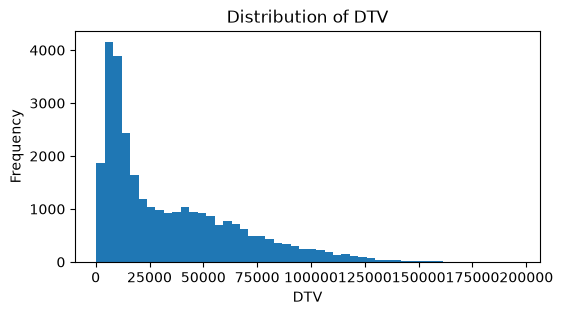

In [8]:
# to check whether data is right-skewed
plt.figure(figsize=(6,3))
plt.hist(df["DTV_Kfz_MobisSo_Q"].dropna(), bins=50)

plt.title("Distribution of DTV")
plt.xlabel("DTV")
plt.ylabel("Frequency")

plt.show()

## (4) find yearly trends

### DTV_Kfz_MobisSo_Q means

Average daily traffic<br>
All vehicles<br>
All days<br>
Both directions<br>

In [9]:
national_median = df.groupby("Jahr")["DTV_Kfz_MobisSo_Q"].median()
print(type(national_median)) # checking what data structured used by pandas to store national_median
print(national_median.head())


<class 'pandas.Series'>
Jahr
2003    22006.0
2004    18720.5
2005    17328.5
2006    18333.0
2007    18676.0
Name: DTV_Kfz_MobisSo_Q, dtype: float64


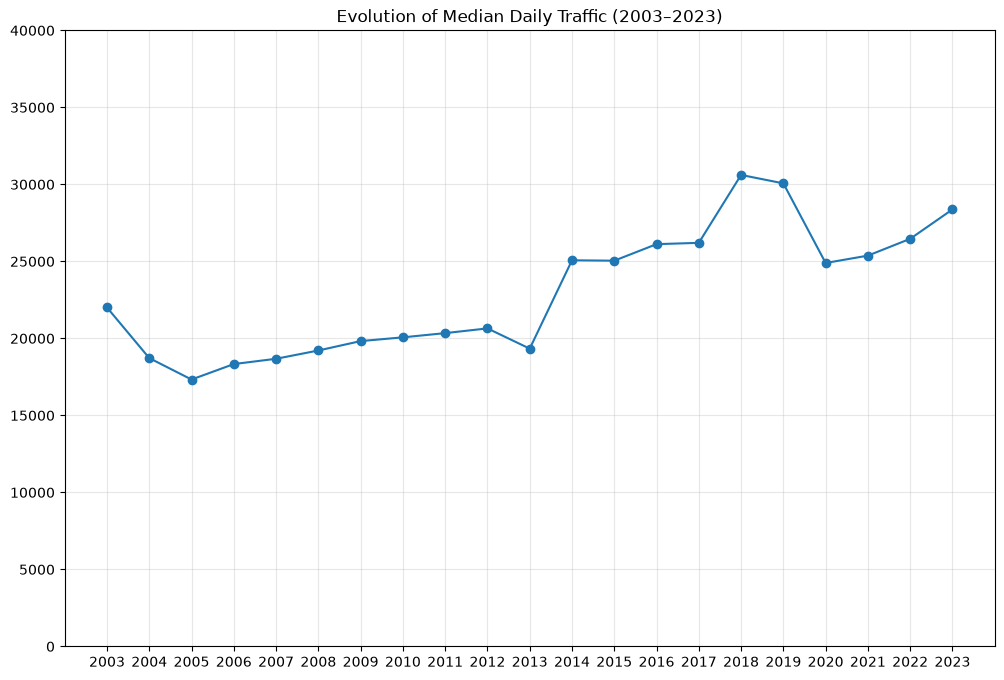

In [10]:
# plot the line graph for the fist findings.
plt.figure(figsize=(12,8))
plt.title("Evolution of Median Daily Traffic (2003–2023)")
plt.plot(national_median.index, national_median.values, marker= 'o')
plt.xticks(range(2003,2024))
plt.ylim(0,40000)
plt.grid(True,alpha=0.3)


In [11]:
# percentage changes in medians
pct_change = national_median.pct_change() * 100
print(pct_change.round(2))

Jahr
2003      NaN
2004   -14.93
2005    -7.44
2006     5.80
2007     1.87
2008     2.88
2009     3.17
2010     1.23
2011     1.37
2012     1.50
2013    -6.36
2014    29.67
2015    -0.10
2016     4.28
2017     0.33
2018    16.83
2019    -1.79
2020   -17.19
2021     1.92
2022     4.30
2023     7.21
Name: DTV_Kfz_MobisSo_Q, dtype: float64


In [12]:
station_count = df.groupby('Jahr')['DZ_Nr'].nunique()
print(station_count)
# even in year 2013-2014 stations are incresed by aproxx 200 new stations still trafic was also incresed!

Jahr
2003    1260
2004    1293
2005    1321
2006    1331
2007    1339
2008    1345
2009    1375
2010    1460
2011    1482
2012    1494
2013    1503
2014    1683
2015    1746
2016    1747
2017    1753
2018    1924
2019    2016
2020    2040
2021    2109
2022    2114
2023    2116
Name: DZ_Nr, dtype: int64


#### by this code we make strong evidence to support our observation about strong sudden increased in traffic median during year 2013-2014.
###### most of the new added roads were Autobahn which holds more traffic than Bundessstrassen.

In [13]:
highways_changes =df.groupby(['Jahr',"Str_Kl"])["DZ_Nr"].nunique()
print(highways_changes) 

Jahr  Str_Kl
2003  A          573
      B          687
2004  A          586
      B          707
2005  A          595
      B          726
2006  A          601
      B          730
2007  A          615
      B          724
2008  A          621
      B          724
2009  A          648
      B          727
2010  A          693
      B          767
2011  A          711
      B          771
2012  A          720
      B          774
2013  A          727
      B          776
2014  A          876
      B          807
2015  A          930
      B          816
2016  A          950
      B          797
2017  A          952
      B          801
2018  A         1125
      B          799
2019  A         1136
      B          880
2020  A         1159
      B          881
2021  A         1227
      B          882
2022  A         1228
      B          886
2023  A         1234
      B          882
Name: DZ_Nr, dtype: int64


In [14]:
print(df.groupby(['Jahr', 'Str_Kl'])['DTV_Kfz_MobisSo_Q'].median())

Jahr  Str_Kl
2003  A         52764.5
      B         10054.0
2004  A         53823.0
      B          9965.0
2005  A         50784.0
      B          9647.0
2006  A         52405.0
      B          9562.0
2007  A         53425.0
      B          9666.0
2008  A         52675.5
      B          9791.0
2009  A         51544.0
      B          9912.0
2010  A         51496.0
      B          9824.0
2011  A         52290.5
      B          9707.0
2012  A         51043.0
      B          9693.5
2013  A         52989.0
      B          9322.0
2014  A         54058.0
      B          9697.0
2015  A         51741.5
      B          9485.5
2016  A         52801.5
      B          9877.5
2017  A         53389.5
      B          9757.0
2018  A         56173.0
      B          9875.0
2019  A         55762.0
      B         10163.0
2020  A         46538.0
      B          8978.5
2021  A         46444.0
      B          8939.5
2022  A         49420.0
      B          9393.0
2023  A         52026.0
   

##### We checked median changes of A and B roads between 2013-2014 but 2014 autobahn had been slightly increased aproxx 4%. Which is not justifying skyrocketed growth in traffic median which was 30%.<br>
##### Now we have to check whether it is affected by null values or not !

In [15]:
print(df.groupby('Jahr')["DTV_Kfz_MobisSo_Q"]
      .apply(lambda s: s.isna().mean().round(3))
      )

Jahr
2003    0.250
2004    0.120
2005    0.098
2006    0.076
2007    0.077
2008    0.030
2009    0.034
2010    0.071
2011    0.044
2012    0.028
2013    0.069
2014    0.055
2015    0.073
2016    0.107
2017    0.155
2018    0.213
2019    0.230
2020    0.200
2021    0.203
2022    0.223
2023    0.264
Name: DTV_Kfz_MobisSo_Q, dtype: float64


##### We verify that even null values are not affecting the traffic growth.<br>
##### Now we are going to check whether traffic was increased by new stations or also on existing roads as well

In [16]:
# This code it gernerated by ChatGPT
stations_2013 = set(df.loc[df["Jahr"] == 2013, "DZ_Nr"])
stations_2014 = set(df.loc[df["Jahr"] == 2014, "DZ_Nr"])

print(len(stations_2013))
print(len(stations_2014))

1503
1683


In [17]:
# This code it gernerated by ChatGPT
common_stations = stations_2013 & stations_2014

print(len(common_stations))

1493


In [18]:
# This code it gernerated by ChatGPT
balanced = df[df["DZ_Nr"].isin(common_stations)]

In [19]:
# This code it gernerated by ChatGPT
balanced.groupby("Jahr")["DZ_Nr"].nunique().loc[2013:2014]

Jahr
2013    1493
2014    1493
Name: DZ_Nr, dtype: int64

##### By this result i am putting my strongest supporting reason: `the increasing number of autobahn increased number of trafic rather than existing`, yes very small percent of growth also seen in existing stations but major differnce is by new added stations<br>

2014 anomaly:

- National median DTV increased by 5,737 vehicles.
- Station count increased from 1,503 to 1,683.
- 149 of the 180 new stations were Autobahn stations.
- A balanced-panel analysis reduced the increase from 5,737 to 1,623 vehicles.
- Therefore, a substantial part of the increase is attributable to changes in station composition.

In [20]:
# This code it gernerated by ChatGPT
balanced.groupby("Jahr")["DTV_Kfz_MobisSo_Q"].median().loc[2013:2014]

Jahr
2013    19550.0
2014    21173.0
Name: DTV_Kfz_MobisSo_Q, dtype: float64

## (5) Finding evolution between Autobahn & Bundesstraße

In [21]:
print(df.groupby(['Jahr', 'Str_Kl'])['DTV_Kfz_MobisSo_Q'].median())

Jahr  Str_Kl
2003  A         52764.5
      B         10054.0
2004  A         53823.0
      B          9965.0
2005  A         50784.0
      B          9647.0
2006  A         52405.0
      B          9562.0
2007  A         53425.0
      B          9666.0
2008  A         52675.5
      B          9791.0
2009  A         51544.0
      B          9912.0
2010  A         51496.0
      B          9824.0
2011  A         52290.5
      B          9707.0
2012  A         51043.0
      B          9693.5
2013  A         52989.0
      B          9322.0
2014  A         54058.0
      B          9697.0
2015  A         51741.5
      B          9485.5
2016  A         52801.5
      B          9877.5
2017  A         53389.5
      B          9757.0
2018  A         56173.0
      B          9875.0
2019  A         55762.0
      B         10163.0
2020  A         46538.0
      B          8978.5
2021  A         46444.0
      B          8939.5
2022  A         49420.0
      B          9393.0
2023  A         52026.0
   

###### A typical Autobahn counting station carries about 5 times as much traffic as a typical Bundesstraße station.

In [22]:
# Transforming the data into proper columns for better understanding
road_class_trend = df.groupby(['Jahr', 'Str_Kl'])['DTV_Kfz_MobisSo_Q'].median().unstack() # by .unstack() it converts Road A & B into columns as shown in result
print(road_class_trend) 

Str_Kl        A        B
Jahr                    
2003    52764.5  10054.0
2004    53823.0   9965.0
2005    50784.0   9647.0
2006    52405.0   9562.0
2007    53425.0   9666.0
2008    52675.5   9791.0
2009    51544.0   9912.0
2010    51496.0   9824.0
2011    52290.5   9707.0
2012    51043.0   9693.5
2013    52989.0   9322.0
2014    54058.0   9697.0
2015    51741.5   9485.5
2016    52801.5   9877.5
2017    53389.5   9757.0
2018    56173.0   9875.0
2019    55762.0  10163.0
2020    46538.0   8978.5
2021    46444.0   8939.5
2022    49420.0   9393.0
2023    52026.0   9442.5


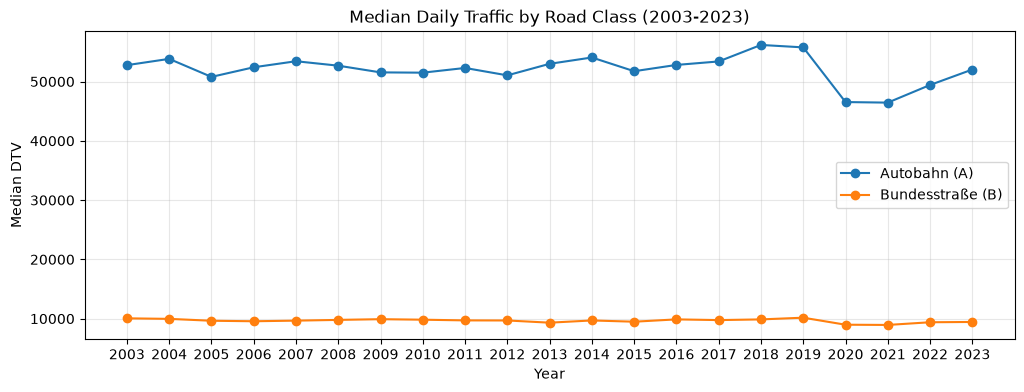

In [23]:
plt.figure(figsize=(12,4))
plt.title("Median Daily Traffic by Road Class (2003-2023)")
plt.plot(road_class_trend.index, road_class_trend['A'], marker = 'o')
plt.plot(road_class_trend.index, road_class_trend['B'], marker= 'o')
plt.xlabel("Year")
plt.ylabel("Median DTV")
plt.legend(["Autobahn (A)", "Bundesstraße (B)"])
plt.xticks(range(2003,2024))
# plt.ylim(0,40000)
plt.grid(True,alpha=0.3)


##### Let's see how much traffic growth or decline had been on both roads in percentage 

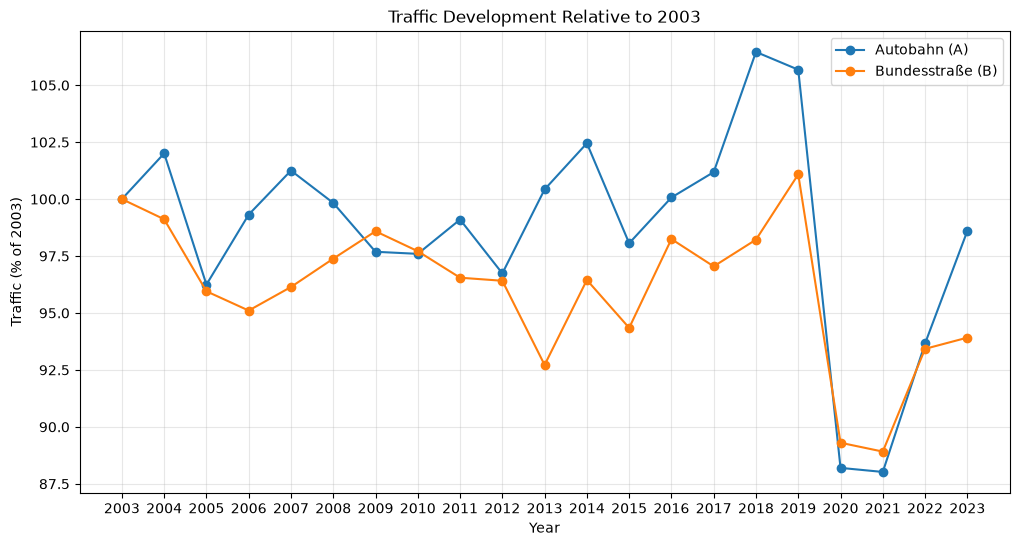

In [24]:
# this code is generated by ChatGPT
A_pct = road_class_trend["A"] / road_class_trend["A"].loc[2003] * 100

B_pct = road_class_trend["B"] / road_class_trend["B"].loc[2003] * 100

plt.figure(figsize=(12,6))

plt.plot(A_pct.index, A_pct, marker="o")
plt.plot(B_pct.index, B_pct, marker="o")

plt.title("Traffic Development Relative to 2003")
plt.xlabel("Year")
plt.ylabel("Traffic (% of 2003)")
plt.legend(["Autobahn (A)", "Bundesstraße (B)"])

plt.xticks(range(2003, 2024))
plt.grid(True, alpha=0.3)

plt.show()

What have we learned from A vs B?

- Autobahn stations consistently carry much higher traffic volumes than Bundesstraße stations.
- Relative traffic development was similar for both road classes.
- Autobahn traffic experienced a stronger decline in 2020.
- Autobahn traffic recovered more strongly after 2020.
- The growth patterns intersect several times, indicating that neither road class consistently outperformed the other.

## (6) Finding which roads changed the most!

In [25]:
df["Road_ID"] = df["Str_Kl"] + df["Str_Nr"].astype(str)

C:\Users\darsh\AppData\Local\Temp\ipykernel_8948\2045349947.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Road_ID"] = df["Str_Kl"] + df["Str_Nr"].astype(str)


##### Let's find which road seen highest growth year by year

In [53]:
# road wise values
road_traffic = (
    df.groupby(["Road_ID", "Jahr"])["DTV_Kfz_MobisSo_Q"]
      .median()
      .unstack()
)
print(road_traffic)

Jahr         2003      2004     2005     2006     2007     2008     2009  \
Road_ID                                                                    
A1        61453.0   59833.5  58754.0  69248.0  65542.0  59864.0  68534.0   
A10       44474.5   48526.0  40502.0  47624.0  49987.5  49390.0  51198.0   
A100     164725.5  138086.0      NaN      NaN      NaN      NaN      NaN   
A103          NaN       NaN      NaN      NaN      NaN      NaN      NaN   
A104      51200.0       NaN      NaN      NaN      NaN      NaN      NaN   
...           ...       ...      ...      ...      ...      ...      ...   
B93        8036.0    7156.0   8813.0   6079.0   8434.0   7112.0   7519.0   
B94        5158.0    5203.0   5063.0   4154.0   4842.0      NaN   4099.0   
B95        3902.5    4337.0   3911.0   3540.0   3013.0   2642.5   2534.5   
B96       12946.0   11225.0  10527.0   8200.0   8824.5   9007.0   9519.0   
B97        8112.0    7085.0   7197.5   7090.0   4101.0   4255.0   4334.0   

Jahr       

##### Finding percentage growth

In [54]:
#make sure that road should not discontinue within 21 years.
road_traffic.count(axis=1).sort_values(ascending=False)
complete_roads = road_traffic[road_traffic.count(axis=1) == 21]

In [55]:
#percentage variation
percent_change = (
    (complete_roads[2023] - complete_roads[2003])
    / complete_roads[2003]
) * 100

In [56]:
percent_change.tail()

Road_ID
B92   -17.223763
B93    -2.513688
B95   -21.332479
B96   -22.926000
B97    13.424556
dtype: float64

In [57]:
percent_change.sort_values(ascending=False).head(10)

Road_ID
A60     426.433531
B103    388.928133
B49     234.160329
A38     221.948969
B59     191.863678
B258    184.279853
B285    184.097707
A17     149.694226
A81     143.995667
B437    125.797919
dtype: float64

In [58]:
#verifying that road A60 increasing change is real or affecting any other factor
road_traffic.loc["A60"]

Jahr
2003    13969.0
2004    15364.0
2005    15351.0
2006    37873.0
2007    38235.5
2008    59247.0
2009    59122.0
2010    58790.0
2011    55531.0
2012    54713.0
2013    41731.0
2014    65002.0
2015    64629.0
2016    67106.0
2017    67356.0
2018    69569.0
2019    82128.0
2020    65765.0
2021    67760.5
2022    71728.5
2023    73537.5
Name: A60, dtype: float64

In [59]:
#checking difference of stations over the years
x= df[df["Road_ID"] == "A60"].groupby("Jahr")["DZ_Nr"].nunique()
print(x)

Jahr
2003     6
2004     6
2005     6
2006     6
2007     6
2008     7
2009     7
2010     7
2011     7
2012     7
2013     7
2014    15
2015    15
2016    16
2017    16
2018    19
2019    19
2020    19
2021    19
2022    19
2023    19
Name: DZ_Nr, dtype: int64


In [60]:
#verifying that stations are same or different in A60 
df[df["Road_ID"] == "A60"].groupby("Jahr")["DZ_Nr"].unique()

Jahr
2003                 [6991, 7110, 7013, 7109, 7063, 7950]
2004                 [6991, 7787, 7110, 7109, 7560, 7950]
2005                 [6991, 7787, 7110, 7109, 7560, 7950]
2006                 [6991, 7787, 7110, 7109, 7560, 7950]
2007                 [6991, 7787, 7110, 7109, 7560, 7950]
2008           [6991, 7787, 6993, 7110, 7109, 7560, 7950]
2009           [6991, 7787, 6993, 7110, 7109, 7560, 7950]
2010           [6991, 7787, 6993, 7110, 7109, 7560, 7950]
2011           [6991, 7787, 6993, 7110, 7109, 7560, 7950]
2012           [6991, 7787, 6993, 7110, 7109, 7560, 7950]
2013           [6991, 7787, 6993, 7110, 7109, 7560, 7950]
2014    [7401, 6991, 7928, 7409, 7787, 7633, 6993, 790...
2015    [7401, 6991, 7928, 7409, 7787, 7633, 6993, 790...
2016    [7401, 6991, 7928, 7409, 7787, 7633, 6993, 790...
2017    [7401, 6991, 7928, 7409, 7787, 7633, 6993, 790...
2018    [7401, 6991, 7928, 7409, 7787, 7633, 6993, 790...
2019    [7401, 6991, 7928, 7409, 7787, 7633, 6993, 790...
2020    [

###### by above code it is proved that old stations are discontinued and added new which is increses trafic over the year


#### top 5 increasing roads over the year graph

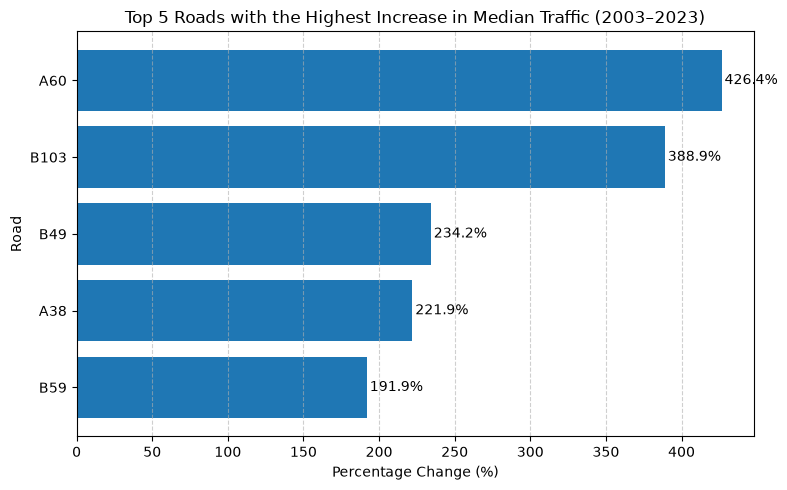

In [64]:
# plotting graph for top 5 traffic increasing roads over the year
top5 = percent_change.sort_values(ascending=False).head(5)
plt.figure(figsize=(8,5))
bar = plt.barh(top5.index, top5.values)

plt.xlabel("Percentage Change (%)")
plt.ylabel("Road")
plt.title("Top 5 Roads with the Highest Increase in Median Traffic (2003–2023)")

plt.gca().invert_yaxis()

# Add percentage labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 2,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}%",
        va="center"
    )

plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

#### top 5 traffic decreasing roads over the years

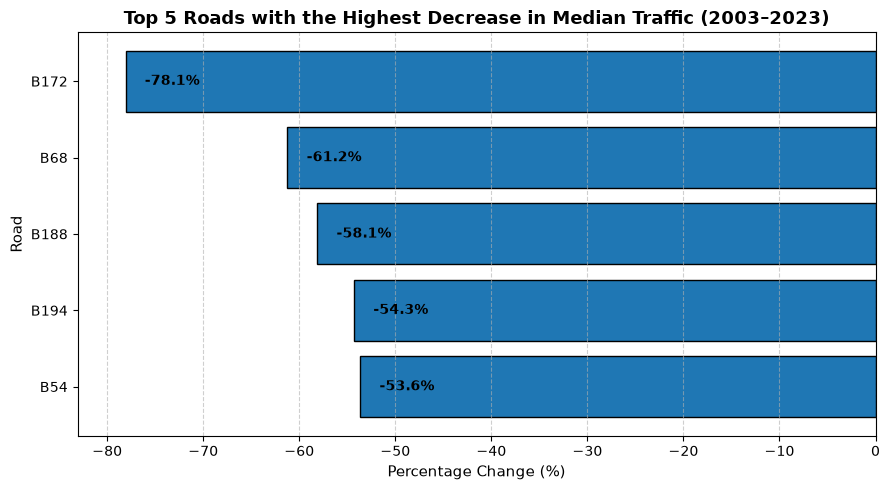

In [65]:
#Top 5 roads with the highest percentage decrease

top5 = percent_change.sort_values(ascending=True).head(5)
plt.figure(figsize=(9,5))

bars = plt.barh(
    top5.index,
    top5.values,
    edgecolor="black",
)

plt.xlabel("Percentage Change (%)", fontsize=11)
plt.ylabel("Road", fontsize=11)
plt.title(
    "Top 5 Roads with the Highest Decrease in Median Traffic (2003–2023)", fontsize=13,weight="bold"
)
# Highest decrease at the top
plt.gca().invert_yaxis()

# Add percentage labels
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 2,                               # Slightly right of the bar end
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold"
    )

# Grid
plt.grid(axis="x", linestyle="--", alpha=0.6)

# Extra space on the left for labels
plt.xlim(top5.min() - 5, 0)

plt.tight_layout()
plt.show()


##### 

## (7) Specialities & correlations

In [32]:
traffic_median = df.groupby('Jahr')['DTV_Kfz_MobisSo_Q'].median()
print(traffic_median)
print(station_count)

Jahr
2003    22006.0
2004    18720.5
2005    17328.5
2006    18333.0
2007    18676.0
2008    19214.0
2009    19824.0
2010    20068.0
2011    20342.0
2012    20648.0
2013    19334.0
2014    25071.0
2015    25045.5
2016    26118.5
2017    26204.5
2018    30613.5
2019    30066.0
2020    24896.5
2021    25374.0
2022    26466.0
2023    28374.0
Name: DTV_Kfz_MobisSo_Q, dtype: float64
Jahr
2003    1260
2004    1293
2005    1321
2006    1331
2007    1339
2008    1345
2009    1375
2010    1460
2011    1482
2012    1494
2013    1503
2014    1683
2015    1746
2016    1747
2017    1753
2018    1924
2019    2016
2020    2040
2021    2109
2022    2114
2023    2116
Name: DZ_Nr, dtype: int64


In [33]:
# combining columns traffic_median adn station_count into single dataFrame
correlation_table = pd.DataFrame({
    "Stations": station_count,
    "Traffic" : traffic_median
})
print(correlation_table.head())

      Stations  Traffic
Jahr                   
2003      1260  22006.0
2004      1293  18720.5
2005      1321  17328.5
2006      1331  18333.0
2007      1339  18676.0


In [34]:
correlation_table["Stations"].corr(
    correlation_table["Traffic"]
)

np.float64(0.8717005321656742)

In [35]:
total_traffic = df.groupby('Jahr')["DTV_Kfz_MobisSo_Q"].median()
heavy_transport_traffic = df.groupby('Jahr')['DTV_SV_MobisSo_Q'].median()
truck_share = (heavy_transport_traffic / total_traffic ) * 100
print(truck_share)

Jahr
2003    9.915478
2004    9.908923
2005    9.591136
2006    9.507446
2007    9.787963
2008    9.732487
2009    9.236279
2010    9.557504
2011    9.404188
2012    9.177644
2013    9.201407
2014    9.465119
2015    9.444810
2016    9.330551
2017    9.257952
2018    9.590540
2019    8.820595
2020    9.880907
2021    9.714669
2022    9.085241
2023    9.045253
dtype: float64


In [36]:
truck_share_roads = (
    df.groupby("Str_Nr")["DTV_SV_MobisSo_Q"].median()
    /
    df.groupby("Str_Nr")["DTV_Kfz_MobisSo_Q"].median()
) * 100

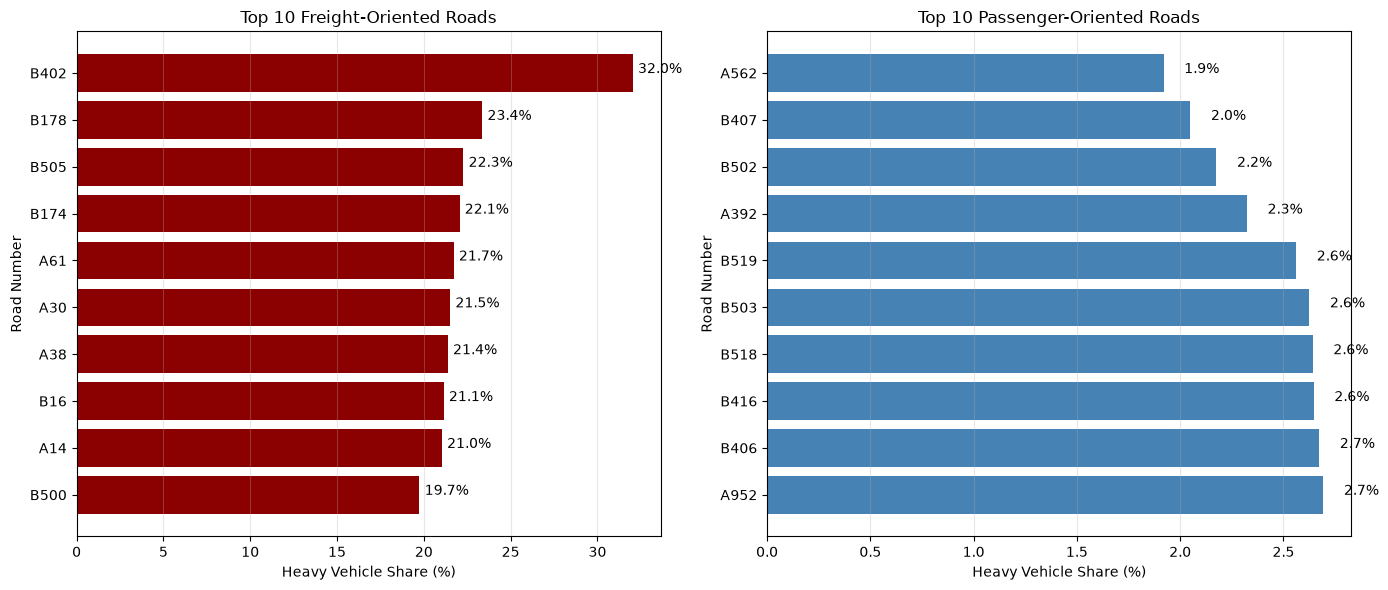

In [37]:
# heavy vehicle traffic analysis
top_truck = truck_share_roads.sort_values(ascending=False).head(10)
bottom_truck = truck_share_roads.sort_values().head(10)

top_labels = []

for road in top_truck.index:
    road_type = df[df["Str_Nr"] == road]["Str_Kl"].mode().iloc[0]
    top_labels.append(f"{road_type}{road}")

bottom_labels = []

for road in bottom_truck.index:
    road_type = df[df["Str_Nr"] == road]["Str_Kl"].mode().iloc[0]
    bottom_labels.append(f"{road_type}{road}")

top_truck = truck_share_roads.sort_values(ascending=False).head(10)
bottom_truck = truck_share_roads.sort_values().head(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Freight-oriented roads
ax[0].barh(
    top_labels,
    top_truck.values,
    color="darkred"
)
ax[0].invert_yaxis()
ax[0].set_title("Top 10 Freight-Oriented Roads")
ax[0].set_xlabel("Heavy Vehicle Share (%)")
ax[0].set_ylabel("Road Number")
ax[0].grid(axis="x", alpha=0.3)
for i, v in enumerate(top_truck.values):
    ax[0].text(v + 0.3, i, f"{v:.1f}%")

# Passenger-oriented roads
ax[1].barh(
    bottom_labels,
    bottom_truck.values,
    color="steelblue"
)
ax[1].invert_yaxis()
ax[1].set_title("Top 10 Passenger-Oriented Roads")
ax[1].set_xlabel("Heavy Vehicle Share (%)")
ax[1].set_ylabel("Road Number")
ax[1].grid(axis="x", alpha=0.3)
for i, v in enumerate(bottom_truck.values):
    ax[1].text(v + 0.1, i, f"{v:.1f}%")

plt.tight_layout()
plt.show()

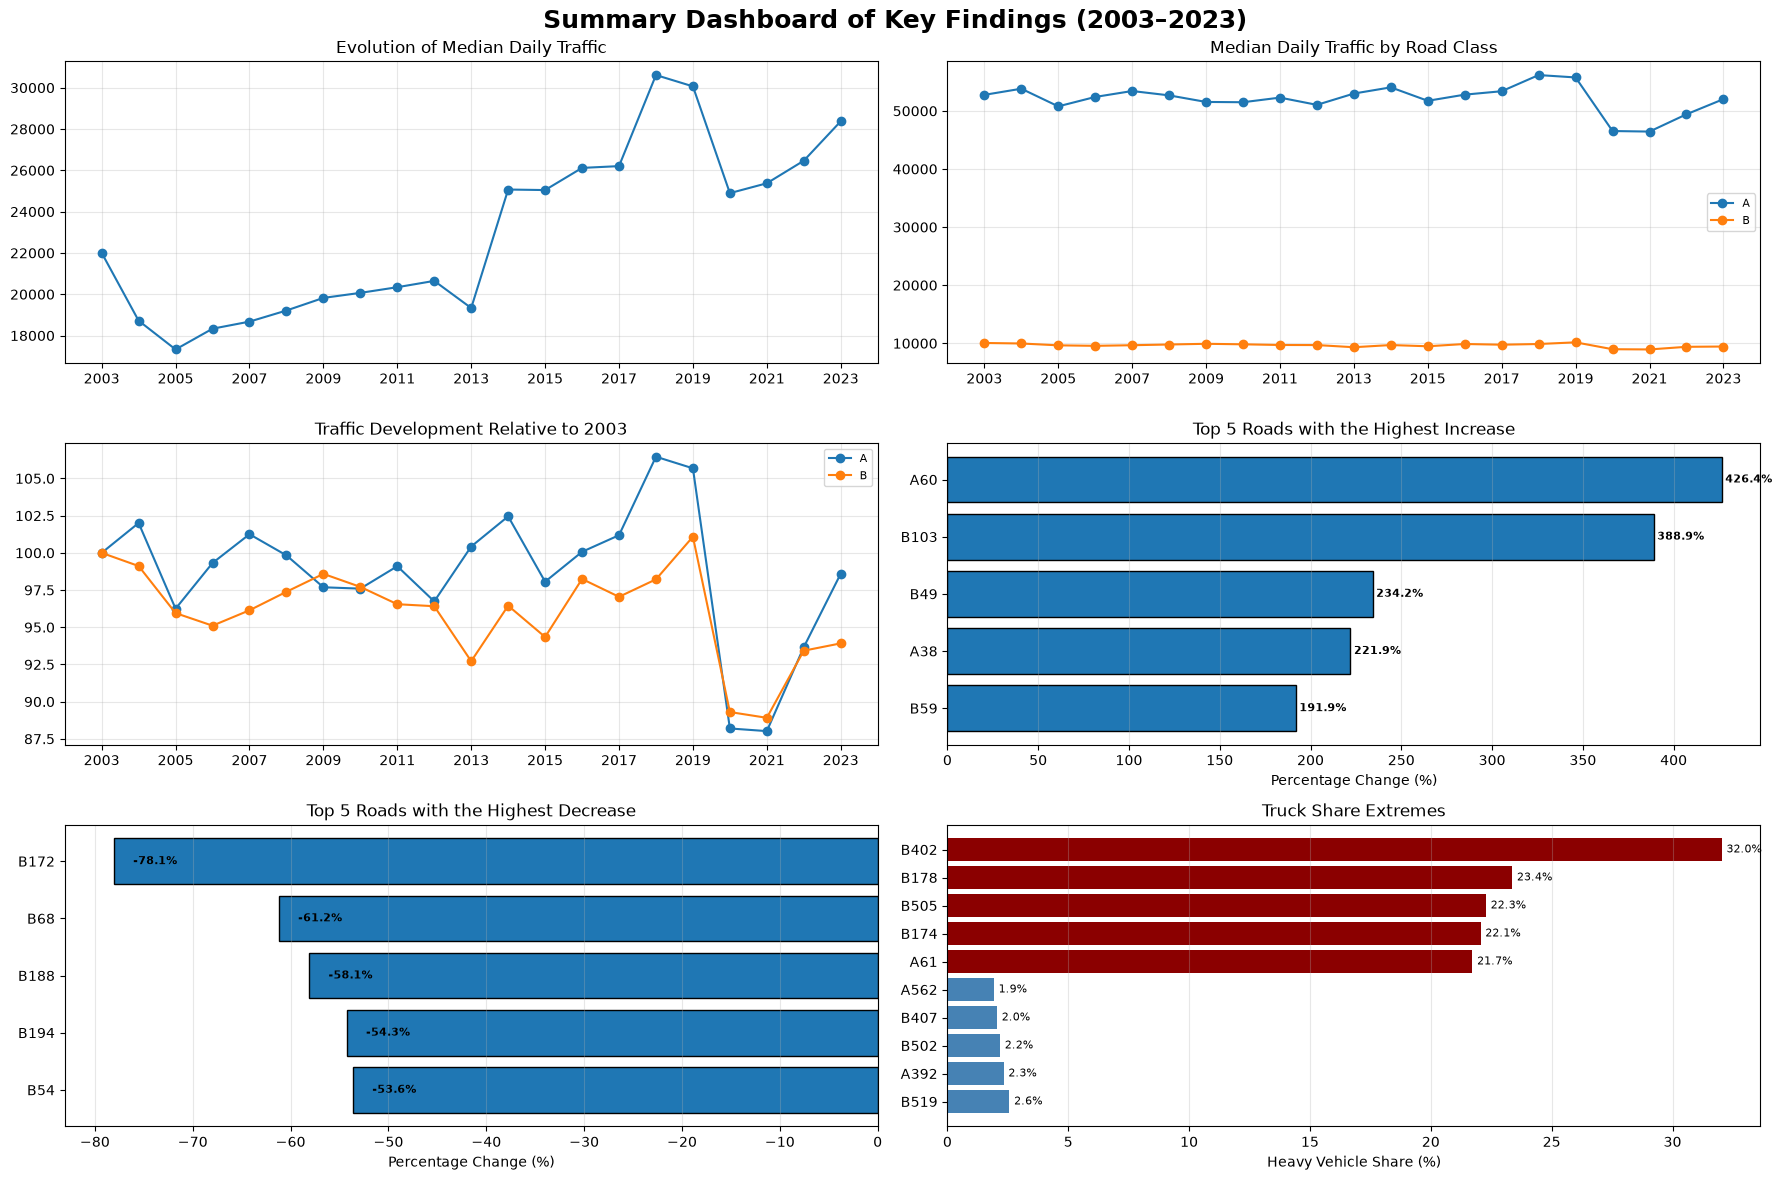

In [77]:
# This dashboard created by ChatGPT

fig, ax = plt.subplots(3, 2, figsize=(18, 12))

# =====================================================
# Graph 1: National Median Traffic
# =====================================================

ax[0,0].plot(
    national_median.index,
    national_median.values,
    marker='o'
)

ax[0,0].set_title("Evolution of Median Daily Traffic")
ax[0,0].set_xticks(range(2003, 2024, 2))
ax[0,0].grid(True, alpha=0.3)

# =====================================================
# Graph 2: Median Traffic by Road Class
# =====================================================

ax[0,1].plot(
    road_class_trend.index,
    road_class_trend['A'],
    marker='o'
)

ax[0,1].plot(
    road_class_trend.index,
    road_class_trend['B'],
    marker='o'
)

ax[0,1].set_title("Median Daily Traffic by Road Class")
ax[0,1].legend(["A", "B"], fontsize=8)
ax[0,1].set_xticks(range(2003, 2024, 2))
ax[0,1].grid(True, alpha=0.3)

# =====================================================
# Graph 3: Relative Growth
# =====================================================

A_pct = road_class_trend["A"] / road_class_trend["A"].loc[2003] * 100
B_pct = road_class_trend["B"] / road_class_trend["B"].loc[2003] * 100

ax[1,0].plot(
    A_pct.index,
    A_pct,
    marker="o"
)

ax[1,0].plot(
    B_pct.index,
    B_pct,
    marker="o"
)

ax[1,0].set_title("Traffic Development Relative to 2003")
ax[1,0].legend(["A", "B"], fontsize=8)
ax[1,0].set_xticks(range(2003, 2024, 2))
ax[1,0].grid(True, alpha=0.3)

# =====================================================
# Graph 4: Top 5 Increasing Roads
# =====================================================

top5_inc = percent_change.sort_values(ascending=False).head(5)

bars = ax[1,1].barh(
    top5_inc.index,
    top5_inc.values,
    edgecolor="black"
)

ax[1,1].invert_yaxis()

for bar in bars:
    width = bar.get_width()
    ax[1,1].text(
        width + 2,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}%",
        va="center",
        fontsize=8,
        fontweight="bold"
    )

ax[1,1].set_title("Top 5 Roads with the Highest Increase")
ax[1,1].set_xlabel("Percentage Change (%)")
ax[1,1].grid(axis="x", alpha=0.3)

# =====================================================
# Graph 5: Top 5 Decreasing Roads
# =====================================================

top5_dec = percent_change.sort_values(ascending=True).head(5)

bars = ax[2,0].barh(
    top5_dec.index,
    top5_dec.values,
    edgecolor="black"
)

ax[2,0].invert_yaxis()

for bar in bars:
    width = bar.get_width()
    ax[2,0].text(
        width + 2,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}%",
        va="center",
        ha="left",
        fontsize=8,
        fontweight="bold"
    )

ax[2,0].set_xlim(top5_dec.min() - 5, 0)

ax[2,0].set_title("Top 5 Roads with the Highest Decrease")
ax[2,0].set_xlabel("Percentage Change (%)")
ax[2,0].grid(axis="x", alpha=0.3)

# =====================================================
# Graph 6: Freight vs Passenger Roads
# =====================================================

top_truck = truck_share_roads.sort_values(ascending=False).head(5)
bottom_truck = truck_share_roads.sort_values().head(5)

labels = top_labels[:5] + bottom_labels[:5]
values = list(top_truck.values) + list(bottom_truck.values)

# Red = Freight-oriented
# Blue = Passenger-oriented
colors = (
    ["darkred"] * len(top_truck)
    + ["steelblue"] * len(bottom_truck)
)

bars = ax[2,1].barh(
    labels,
    values,
    color=colors
)

# Add percentage labels
for bar in bars:
    width = bar.get_width()
    ax[2,1].text(
        width + 0.2,
        bar.get_y() + bar.get_height()/2,
        f"{width:.1f}%",
        va="center",
        fontsize=8
    )

ax[2,1].invert_yaxis()

ax[2,1].set_title("Truck Share Extremes")
ax[2,1].set_xlabel("Heavy Vehicle Share (%)")
ax[2,1].grid(axis="x", alpha=0.3)

plt.suptitle(
    "Summary Dashboard of Key Findings (2003–2023)",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## finding correlations between stations and vehicle types using heatmap

In [66]:
correlation_table = pd.DataFrame({
    "Stations": df.groupby("Jahr")["DZ_Nr"].nunique(),
    "Traffic": df.groupby("Jahr")["DTV_Kfz_MobisSo_Q"].median(),
    "Heavy": df.groupby("Jahr")["DTV_SV_MobisSo_Q"].median()
})

In [67]:
correlation_table["Bus"] = (
    df["DTV_Bus_Ri1"] + df["DTV_Bus_Ri2"]
).groupby(df["Jahr"]).median()

correlation_table["LoA"] = (
    df["DTV_LoA_Ri1"] + df["DTV_LoA_Ri2"]
).groupby(df["Jahr"]).median()

correlation_table["Lzg"] = (
    df["DTV_Lzg_Ri1"] + df["DTV_Lzg_Ri2"]
).groupby(df["Jahr"]).median()

correlation_table["Sat"] = (
    df["DTV_Sat_Ri1"] + df["DTV_Sat_Ri2"]
).groupby(df["Jahr"]).median()

In [68]:
correlation_table.head()

,Stations,Traffic,Heavy,Bus,LoA,Lzg,Sat
Jahr,,,,,,,
2003,1260,22006.0,2182.0,95.0,780.0,1187.0,610.5
2004,1293,18720.5,1855.0,73.0,635.5,906.5,547.5
2005,1321,17328.5,1662.0,62.0,583.0,894.0,578.0
2006,1331,18333.0,1743.0,67.0,597.0,965.0,643.0
2007,1339,18676.0,1828.0,65.0,611.0,1078.0,684.0


In [69]:
corr_matrix = correlation_table.corr()
corr_matrix

,Stations,Traffic,Heavy,Bus,LoA,Lzg,Sat
Stations,1.000000,0.871701,0.848937,-0.463581,0.181100,0.880727,0.934754
Traffic,0.871701,1.000000,0.982195,-0.011930,0.575772,0.950237,0.892988
Heavy,0.848937,0.982195,1.000000,-0.012628,0.640441,0.958272,0.871339
Bus,-0.463581,-0.011930,-0.012628,1.000000,0.652391,-0.133171,-0.354597
LoA,0.181100,0.575772,0.640441,0.652391,1.000000,0.496085,0.232187
Lzg,0.880727,0.950237,0.958272,-0.133171,0.496085,1.000000,0.952367
Sat,0.934754,0.892988,0.871339,-0.354597,0.232187,0.952367,1.000000


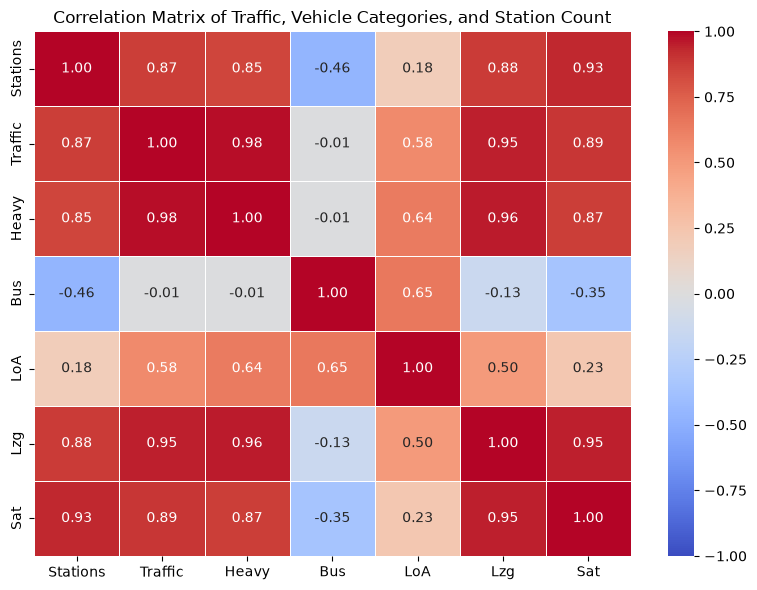

In [76]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corr_matrix, 
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Traffic, Vehicle Categories, and Station Count")
plt.tight_layout()
plt.show()

## Correlation Analysis of Traffic, Vehicle Categories, and Station Count

To further investigate the relationships between traffic characteristics, a Pearson correlation matrix was computed using yearly median values from 2003 to 2023. The analysis included the number of counting stations, total traffic, heavy vehicle traffic, buses, trucks without trailers (LoA), articulated trucks (Lzg), and semi-trailer trucks (Sat).

### Key Findings

- **Station count showed a strong positive correlation with total traffic (r = 0.87)** and **heavy vehicle traffic (r = 0.85)**. This suggests that years with more counting stations were also associated with higher observed traffic volumes, supporting the earlier observation that changes in station coverage can influence national traffic statistics.

- **Total traffic and heavy vehicle traffic exhibited an almost perfect positive correlation (r = 0.98)**. This indicates that heavy vehicle traffic closely followed the overall traffic trend throughout the study period, suggesting that freight transport is a major contributor to long-term traffic growth.

- **Articulated trucks (Lzg) also showed a very strong correlation with both total traffic (r = 0.95) and heavy vehicles (r = 0.96)**, highlighting their importance within the freight transport sector.

- **Semi-trailer trucks (Sat) demonstrated strong positive correlations with station count (r = 0.93), total traffic (r = 0.89), and articulated trucks (r = 0.95)**. These results indicate that different categories of heavy freight vehicles generally increased together over the study period.

- **Trucks without trailers (LoA) displayed moderate positive correlations** with total traffic (r = 0.58) and heavy vehicles (r = 0.64), suggesting that this vehicle category increased over time but less consistently than articulated and semi-trailer trucks.

- **Bus traffic exhibited weak or negative correlations with most variables**. In particular, bus traffic showed almost no relationship with total traffic (r = -0.01) and heavy vehicles (r = -0.01), while its correlation with station count was moderately negative (r = -0.46). This indicates that bus traffic followed a different long-term trend than overall road traffic and freight transport.

### Conclusion

The correlation analysis reveals that total traffic growth is strongly associated with heavy freight vehicle categories, particularly articulated and semi-trailer trucks. Additionally, the positive relationship between station count and traffic supports the earlier finding that changes in the monitoring network can influence aggregated national traffic measurements. In contrast, bus traffic follows a distinct trend and appears largely independent of overall traffic growth.

---

## AI Assistance Declaration

In accordance with the course policy on AI usage, this section documents where **ChatGPT (OpenAI)** was used during this traffic analysis project.

**Parts developed with AI assistance (marked with a `# NOTE` comment in the code where applicable):**

- Development of the **summary dashboard**, including arranging multiple analyses into a single 3 × 2 visualization.
- Implementation of the **Top 5 Roads with the Highest Increase** and **Top 5 Roads with the Highest Decrease** using percentage change in median traffic between 2003 and 2023.
- Creation of the **correlation matrix** and **heatmap** to investigate relationships between station count, total traffic, heavy vehicles, and freight vehicle categories.
- Suggestions for improving figure formatting, including titles, axis labels, annotations, layout, and overall visualization quality.

**Parts written / understood without AI assistance:**

- Data loading, preprocessing, handling missing values, and selecting relevant variables.
- Calculation of yearly median traffic, national traffic trends, road class analysis, relative growth analysis, truck share analysis, and percentage change calculations.
- Identification of unique roads using the combination of `Str_Kl` and `Str_Nr`.
- Interpretation of the results, validation of the methodology, and all conclusions presented in the report.

**My understanding:**

I understand every part of the implemented code and can explain the methodology, calculations, visualizations, and interpretation of the results. AI assistance was used to improve code implementation and visualization design, while the analytical decisions, validation of the methodology, and final conclusions were made by me.

*Tool used: ChatGPT (OpenAI). AI-assisted sections are identified with `# NOTE` comments where applicable.*

# TASK – 02  All autobahns — bottlenecks on the Germany map

In Task 1 we looked at how traffic *evolved*. Task 2 asks a different question: **where are the
bottlenecks, and what kind is each one?** A bottleneck is a spot where the road cannot carry the
traffic that wants through. It leaves two fingerprints in the count data, so we build two detectors:

* **traffic jams** — a lane that carries a lot of cars every day (a *permanent* capacity problem)
* **construction sites** — one station whose traffic suddenly drops far below the rest of the country (a *temporary* obstruction)

Each step is one short cell with one idea, with short comments inside the code.

### Step 1 — Import the tools
We use **pandas** for the table and **matplotlib** for the charts and map. `json`, `os`, `urllib` are only for the Germany outline later.

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import json, os, urllib.request

In [40]:
COLS = ["Jahr",                # year
        "DZ_Nr",               # station number (id)
        "DZ_Name",             # station name
        "Str_Kl",              # road class: A = autobahn, B = federal road
        "Str_Nr",              # road number: 9 = A9
        "Anz_Fs_Q",            # number of lanes
        "DTV_Kfz_MobisSo_Q",   # average daily traffic (all vehicles)
        "Koor_WGS84_N",        # GPS latitude
        "Koor_WGS84_E"]        # GPS longitude

raw = pd.read_csv("Zeitreihe.csv", encoding="latin1",   # German file -> Latin-1
                  sep=";",                # columns separated by ;
                  decimal=",", thousands=".",  # German number format (1.234,5)
                  usecols=COLS, low_memory=False)        # read only the 9 columns
raw.head(3)                                # peek at the first rows

,Jahr,DZ_Nr,DZ_Name,Str_Kl,Str_Nr,Anz_Fs_Q,DTV_Kfz_MobisSo_Q,Koor_WGS84_N,Koor_WGS84_E
0,2023,2218,AD HH-Südost (O),A,1,6,NaN,53.507548,10.087183
1,2023,2217,AD HH-Südost (W),A,1,8,NaN,53.509414,10.055028
2,2023,5675,AK Leverkusen (O),A,1,6,NaN,51.063307,7.071186


### Kept road class `A` and gave the long German names short handles. The print line confirms how many autobahns and stations we have.

In [41]:
cars = raw[raw["Str_Kl"] == "A"].copy()        # keep only autobahns ("A")
cars = cars.rename(columns={                   # short, easy handles
    "DTV_Kfz_MobisSo_Q": "DTV",     # daily traffic
    "Anz_Fs_Q":          "lanes",   # number of lanes
    "Koor_WGS84_N":      "lat",     # latitude
    "Koor_WGS84_E":      "lon"})    # longitude
print("autobahns:", cars["Str_Nr"].nunique(), " stations:", cars["DZ_Nr"].nunique())  # how many

autobahns: 117  stations: 1271


### Removed rows without a measurement
Drop rows with no traffic value so every remaining row can be analysed.

In [42]:
cars = cars.dropna(subset=["DTV", "lat", "lon"])   # drop rows missing traffic or position
print("rows we can use:", len(cars))

rows we can use: 14925


###  Kept each station's most recent year
Sort by year and keep the **newest** row of each station — the latest known state of every spot.

In [43]:
# sort by year, then take the last (newest) row of every station
latest = cars.sort_values("Jahr").groupby("DZ_Nr").tail(1).copy()
print("one row per station:", len(latest))

one row per station: 1246


## Signal 1 — traffic jams

A jam-prone spot carries many cars **per lane**, day after day.

### Traffic per lane
A jam is about how *full* a lane is, so we divide daily traffic by lanes: **vehicles per lane per day**.

In [44]:
latest["load"] = latest["DTV"] / latest["lanes"]   # cars per lane per day
latest[["DZ_Name", "DTV", "lanes", "load"]].head(3)  # preview a few rows

,DZ_Name,DTV,lanes,load
33606,AS Worms (S),54222.0,4,13555.50
33410,München-Perlach (S),42139.0,4,10534.75
33383,Oy-Süd (O),5448.0,4,1362.00


### — Flag the busiest 10% of lanes
The **90th percentile** sets the cut-off from the data itself; busier lanes are traffic-jam bottlenecks.

In [45]:
jam_line = latest["load"].quantile(0.90)     # 90th percentile = busiest 10% of lanes
latest["jam"] = latest["load"] >= jam_line   # True for the busy ones = traffic jam
print("jam threshold:", round(jam_line),
      " | traffic-jam bottlenecks:", int(latest["jam"].sum()))

jam threshold: 17616  | traffic-jam bottlenecks: 125


## Signal 2 — construction sites

One station drops sharply for a year while lanes are closed. But 2020 dropped the **whole country** (COVID), so we measure the national change first, then look for stations that fell *much more*.

###  Each station's traffic, year by year
Reshape into a grid (**stations × years**) and take the year-to-year change — the raw signal for sudden drops.

In [46]:
table = cars.pivot_table(index="DZ_Nr", columns="Jahr", values="DTV")
yoy = table.pct_change(axis=1, fill_method=None)   # year-to-year % change (no gap-filling)
yoy.iloc[:3, -5:]                                  # peek: 3 stations, last 5 years

Jahr,2019,2020,2021,2022,2023
DZ_Nr,,,,,
101,NaN,NaN,NaN,0.021981,0.043175
102,0.000134,NaN,NaN,0.051741,0.043877
103,NaN,NaN,NaN,0.053738,0.047024


###  The nationwide change each year
The **median** change captures the whole country each year — most visibly the **−16% COVID drop in 2020** — which we must remove first.

In [47]:
national = yoy.median(axis=0)        # median change of all stations, per year (the COVID effect)
print("2019:", round(national.get(2019,0)*100,1), "%   2020:",
      round(national.get(2020,0)*100,1), "%   2021:", round(national.get(2021,0)*100,1), "%")

2019: 0.4 %   2020: -15.9 %   2021: 3.8 %


### How far each station fell *beyond* the country
Subtract the national change; a station that *still* fell **≥15% more** is a local event — a **construction site**.

In [48]:
# NOTE: developed with AI assistance (Claude) — see the AI declaration at the bottom.
extra = yoy.sub(national, axis=1)     # remove the nationwide change from each station
biggest_drop = extra.min(axis=1)     # each station's worst year (most negative)
# a station that fell 15% MORE than the country = a local construction site
constr_stations = biggest_drop[biggest_drop <= -0.15].index   # those stations' ids
latest["constr"] = latest["DZ_Nr"].isin(constr_stations)      # mark them
print("construction sites:", int(latest["constr"].sum()))

construction sites: 46


### Count the bottlenecks
Report how many traffic jams and construction sites, and the total.

In [49]:
print("traffic jams      :", int(latest["jam"].sum()))         # Signal 1 hits
print("construction sites:", int(latest["constr"].sum()))      # Signal 2 hits
print("total             :", int((latest["jam"] | latest["constr"]).sum()))  # either one

traffic jams      : 125
construction sites: 46
total             : 166


## The map

Now the *locating* part — every detected bottleneck on a map of Germany.

### Load the outline of Germany
Read a saved outline (download once if missing). No internet → the map still shows the points without the border.

In [50]:
# NOTE: developed with AI assistance (Claude) — **prmopt** = "Find a Germany outline for the map; if missing, download it once. Then read the saved border and return the outer lines of all polygons "
def load_outline():
    """Read the saved Germany border; if missing, download it once."""
    if not os.path.exists("germany_outline.geojson"):      # no local copy yet?
        url = ("https://raw.githubusercontent.com/isellsoap/deutschlandGeoJSON/"
               "main/1_deutschland/4_niedrig.geo.json")
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            data = urllib.request.urlopen(req, timeout=30).read()   
            open("germany_outline.geojson", "wb").write(data)       # save for next time / offline
        except Exception as e:
            print("(no internet, map will show points only)", e)
            return []                                               # graceful fallback
    gj = json.load(open("germany_outline.geojson"))                 # read the saved border
    rings = []
    for feature in gj["features"]:
        geom = feature["geometry"]
        # a country can be one or many polygons (mainland + islands)
        polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        for poly in polygons:
            rings.append(poly[0])     # keep the outer border line of each polygon
    return rings

border = load_outline()
print("border pieces:", len(border))

border pieces: 20


### Draw the map
Layer the picture: grey **outline**, faint **stations**, then **construction (orange)** and **jams (red)** on top.

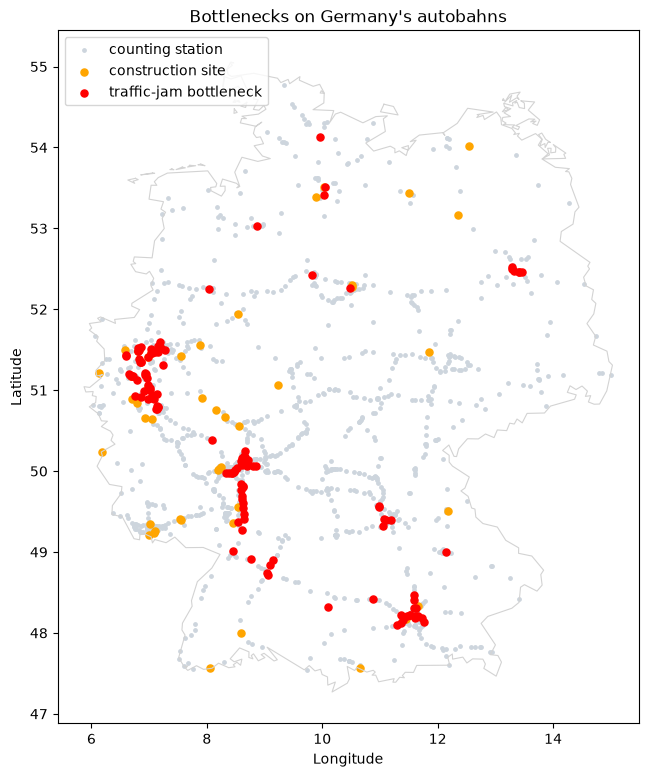

In [51]:
plt.figure(figsize=(7.5, 9))           # tall canvas (Germany is taller than wide)

# 1) the country outline
for ring in border:
    xs = [point[0] for point in ring]  # longitudes
    ys = [point[1] for point in ring]  # latitudes
    plt.plot(xs, ys, color="lightgrey", linewidth=0.8)

# 2) all stations as small grey dots
plt.scatter(latest["lon"], latest["lat"], s=6, color="#cdd5dd", label="counting station")

# 3) construction sites (orange) and traffic jams (red) on top
constr = latest[latest["constr"]]      # rows flagged as construction
jams   = latest[latest["jam"]]         # rows flagged as jams
plt.scatter(constr["lon"], constr["lat"], s=26, color="orange", label="construction site")
plt.scatter(jams["lon"], jams["lat"], s=26, color="red", label="traffic-jam bottleneck")

plt.title("Bottlenecks on Germany's autobahns")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.legend(loc="upper left")           # key in the top-left corner
plt.show()

### Which autobahns have the most bottlenecks?
Count flagged stations per road and show the **fifteen worst**.

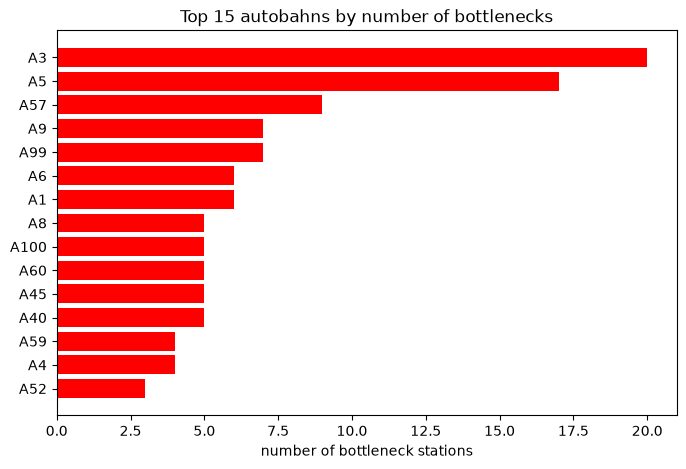

In [52]:
latest["road"] = "A" + latest["Str_Nr"].astype(int).astype(str)   # build name like "A9"
latest["is_bottleneck"] = latest["jam"] | latest["constr"]        # jam OR construction

per_road = latest.groupby("road")["is_bottleneck"].sum()          # count per road
top = per_road.sort_values(ascending=False).head(15).sort_values()# top 15 (small->big for barh)

plt.figure(figsize=(8, 5))
plt.barh(top.index, top.values, color="red")                      # horizontal bars
plt.title("Top 15 autobahns by number of bottlenecks")
plt.xlabel("number of bottleneck stations")
plt.show()

---

## AI Assistance Declaration

In line with the course rule on declaring AI use, this records where an AI assistant (**Claude,
Anthropic**) was used in **Task 2**.

**Parts developed with AI assistance (marked with a `# NOTE` comment in the code):**

* **Signal 2 — construction detection:** the station × year grid, the year-on-year change, and the
  **detrending** by the nationwide median that removes the 2020 COVID drop before flagging local drops.
* **Loading the Germany outline:** download, local caching, polygon parsing, and offline fallback.

**Parts written / understood without AI assistance:** loading and choosing columns, filtering
autobahns, dropping missing rows, keeping each station's latest year, **Signal 1** (traffic per lane +
the top-10 % jam threshold), drawing the map, and the ranking bar chart.

**My understanding:** I can explain every step — what it does and why. The thresholds are deliberate,
adjustable choices: busiest **10 %** of lanes for jams, and a **15 %** extra drop for construction.

*Tool used: Claude (Anthropic). Task 1 AI attributions are noted inline in their own cells.*